# UCS420 Lab Assignment 9 — NLP Text Preprocessing
Enter your roll number and name, then run all cells.

In [1]:
ROLL_NO = 1024170310         # <-- your full roll number
NAME = "Sparsh Kumar"            # <-- your name

import nltk
for pkg in ["punkt", "punkt_tab", "stopwords", "wordnet", "omw-1.4",
            "averaged_perceptron_tagger", "averaged_perceptron_tagger_eng"]:
    nltk.download(pkg, quiet=True)
assert ROLL_NO > 0 and NAME, "Enter your roll number and name first"

### Dataset generator — do not modify

In [2]:
import random, hashlib
import pandas as pd

def generate_dataset(roll_no):
    """Return (DataFrame of tickets, focus ticket IDs, fingerprint) for a roll number. Do not modify."""
    rng = random.Random(int(roll_no))

    subjects = [("LMS", ["LMS", "lms"]), ("Wi-Fi", ["Wi-Fi", "WiFi", "wifi"]), ("VPN", ["VPN"]),
                ("email", ["email", "e-mail"]), ("password", ["password"]), ("portal", ["student portal"]),
                ("projector", ["projector"]), ("laptop", ["laptop"]), ("MATLAB", ["MATLAB", "Matlab"]),
                ("Python", ["Python"]), ("printer", ["printer"]), ("server", ["server"])]
    actions = ["is not working", "keeps disconnecting", "failed to open", "is running slowly",
               "crashes while opening", "stopped responding", "is showing an error", "was working yesterday",
               "has stopped syncing", "keeps asking for login"]
    user_actions = ["cannot access", "can't open", "couldn't connect to", "am unable to use",
                    "tried restarting", "was locked out of", "keep getting logged out of", "reinstalled"]
    contexts = ["after resetting my password", "during the lab", "on my laptop", "since yesterday",
                "after the latest update", "when I use mobile hotspot", "before the assignment deadline",
                "while uploading the file", "after restarting the system", "when connected to campus Wi-Fi"]
    endings = ["Please help.", "Can you check this?", "I have tried several times!", "It worked yesterday.",
               "I don't know what changed.", "The same problem occurs again.", "Is there another solution?",
               "It works on another computer.", "This is urgent.", "Please resolve it."]
    challenges = {
        "negation": ["The Wi-Fi works, but the VPN doesn't.", "Why isn't the portal opening?",
                     "I can't login and I didn't change anything.", "It's not the laptop; it's the server.",
                     "Nothing works and nobody has replied.", "The printer won't print; it isn't jammed."],
        "numbers": ["Python 3.12 was installed yesterday.", "The file is 95.5% uploaded.",
                    "Error code 0x80070005 appears.", "I need Windows 11 by 5.30 p.m. today.",
                    "Only 2 of 30 PCs boot after 3.5 hours.", "Version 2.0.1 crashes at 99%."],
        "identifiers": ["Email me at helpdesk@university.edu.", "See https://lms.thapar.edu/help for details.",
                        "My roll no. is 1023-03-021.", "Ticket #4521 is still open.",
                        "Call me on +91 98765 43210 or 0175-239-3201.",
                        "Write to it.helpdesk@thapar.edu or visit www.thapar.edu/it."],
        "punctuation": ["I tried again... still no response!!!", "The LMS says 'Not Submitted'.",
                        "Dr. Rao's lab PC (No. 14) is down.", "Is it fixed?? Pls reply ASAP :(",
                        "The state-of-the-art lab (Lab-3) is closed.", "Re-installing didn't help; log-in still fails!"],
    }

    tickets = []
    for _ in range(8 + int(roll_no) % 5):
        _, variants = rng.choice(subjects)
        s = rng.choice(variants)
        template = rng.randrange(3)
        if template == 0:
            text = f"{s} {rng.choice(actions)} {rng.choice(contexts)}. {rng.choice(endings)}"
        elif template == 1:
            text = f"I {rng.choice(user_actions)} the {s} {rng.choice(contexts)}. {rng.choice(endings)}"
        else:
            text = f"The {s} {rng.choice(actions)}. {rng.choice(endings)}"
        tickets.append(text[0].upper() + text[1:])
    for category in ["negation", "numbers", "identifiers", "punctuation"]:
        tickets.append(rng.choice(challenges[category]))
    rng.shuffle(tickets)

    df = pd.DataFrame({"Ticket_ID": [f"T{i + 1:02d}" for i in range(len(tickets))], "Ticket_Text": tickets})
    focus = [f"T{i:02d}" for i in sorted(rng.sample(range(1, len(tickets) + 1), 2))]
    fingerprint = hashlib.md5(("|".join(tickets) + str(int(roll_no))).encode()).hexdigest()[:8].upper()
    return df, focus, fingerprint

### Preprocessing pipeline — do not modify

In [3]:
import string
from nltk.tokenize import sent_tokenize, word_tokenize
from nltk.corpus import stopwords

STOP = set(stopwords.words("english"))

def is_punct(token):
    """A token is punctuation if EVERY character in it is in string.punctuation (e.g. '.', '...', '``', "''")."""
    return all(ch in string.punctuation for ch in token)

def process_ticket(text):
    """The official pipeline. Returns sentences, lowercase tokens, punctuation, stopwords and final tokens."""
    sentences = sent_tokenize(text)
    tokens = [t.lower() for s in sentences for t in word_tokenize(s)]
    punct = [t for t in tokens if is_punct(t)]
    stops = [t for t in tokens if t in STOP]
    final = [t for t in tokens if not is_punct(t) and t not in STOP]
    return {"sentences": sentences, "tokens": tokens, "punct": punct, "stops": stops, "final": final}

In [4]:
df, FOCUS, FINGERPRINT = generate_dataset(ROLL_NO)
print(f"Roll number: {ROLL_NO}   Name: {NAME}   Fingerprint: {FINGERPRINT}   Tickets: {len(df)}\n")
print(df.to_string(index=False))
df.to_csv(f"{ROLL_NO}_generated_dataset.csv", index=False)

Roll number: 1024170310   Name: Sparsh Kumar   Fingerprint: ADCD231C   Tickets: 12

Ticket_ID                                                                               Ticket_Text
      T01                                  The LMS has stopped syncing. I have tried several times!
      T02 Student portal is not working after restarting the system. The same problem occurs again.
      T03                            The student portal keeps asking for login. Can you check this?
      T04                                                        Dr. Rao's lab PC (No. 14) is down.
      T05                                                     The Wi-Fi works, but the VPN doesn't.
      T06                       I am unable to use the student portal on my laptop. This is urgent.
      T07                                 The laptop is running slowly. I have tried several times!
      T08                                              See https://lms.thapar.edu/help for details.
      T09       

---
## Q1. Preprocessing pipeline
Run process_ticket() on every ticket and show one table with, per ticket: sentences, tokens, punctuation tokens, stopwords, unique tokens and final tokens, plus a TOTAL row.

In [5]:
from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize,sent_tokenize
import re

In [6]:
info_list = []
stop_words_list = stopwords.words('english')
final_tokens = []
for i in range(len(df)):
    sent = sent_tokenize(df['Ticket_Text'][i])
    tokens = [word for s in sent for word in word_tokenize(s)]
    sent_punctuation = [re.sub(r"[.?!']", "", s) for s in sent]
    new_tokens = [word for s in sent_punctuation for word in word_tokenize(s)]
    token_stop = [word for word in new_tokens if word.lower() not in stop_words_list]

    temp_dict = {}
    temp_dict['Number of Sentences'] = len(sent)
    temp_dict['Number of Tokens'] = len(tokens)
    temp_dict['Number of Punctuation Tokens'] = len(tokens)-len(new_tokens)
    temp_dict['Number of Stop Words'] = len(new_tokens) - len(token_stop)
    temp_dict['Number of Unique Tokens'] = len(set(token_stop))
    temp_dict['Number of Final Tokens'] = len(token_stop)
    final_tokens.extend(token_stop)
    if(i==3):
      print(token_stop)
    info_list.append(temp_dict)
df_info = pd.DataFrame(info_list)
df_info.head(2)


['Dr', 'Raos', 'lab', 'PC', '(', '14', ')']


,Number of Sentences,Number of Tokens,Number of Punctuation Tokens,Number of Stop Words,Number of Unique Tokens,Number of Final Tokens
0,2,12,2,4,6,6
1,2,16,2,7,7,7


**Observe:** Which final tokens in your data are not real words (e.g. n't, 's, ca)? Where do they come from?

*Your answer:* ***In Dr. Rao’s example, the tokens Dr, Raos, lab, PC, (, 14, and ) are produced from the original text. Here, “Raos” is not a separate real word; it likely comes from the name “Rao’s”, where the apostrophe was removed during preprocessing.***

---
## Q2. Regular expressions
On your raw tickets, use re.findall to extract: words longer than 5 letters; all numbers (keep 95.5 and 2.0.1 whole); capitalized words; words starting with a vowel. Then use re.sub to replace emails with <EMAIL>, URLs with <URL> and phone numbers with <PHONE>. Your patterns must also work on TEST_LINES (given in the notebook).

In [7]:
TEST_LINES = [
    "Mail it.helpdesk@thapar.edu or a.b-c@dept.univ.ac.in; visit https://lms.thapar.edu/help or www.thapar.edu/it.",
    "Call +91 98765 43210, +91-98765-43210 or 0175-239-3201. Version 2.0.1 is 95.5% done; fee Rs 1,250.",
    "The state-of-the-art lab isn't open; log-in at 5.30 p.m. didn't work.",
]
all_words = [word for T in df['Ticket_Text'] for word in re.findall(r'\b[a-zA-Z]{6,}\b', T)]

numbers = [word for T in df['Ticket_Text'] for word in re.findall(r'\d\.\d\.\d|\d+\.\d+|\d+', T)]
# storing patterns
capital_words = [word for T in df['Ticket_Text'] for word in re.findall(r'\b[A-Z][a-z]*\b', T)]
vowel_words = [word for T in df['Ticket_Text'] for word in re.findall(r'\b[AEIOUaeiou][a-zA-Z]*\b', T)]


ticket_text_URL_number_free = [re.sub(r'\+\d{2}\s\d{5}\s\d{5}|\+\d{2}-\d{5}-\d{5}|\d{4}-\d{3}-\d{4}|\b[A-Za-z0-9.-]+@[A-Za-z0-9.-]+\.[A-Za-z]{2,}\b', '.', T) for T in df['Ticket_Text']]
# Removing leftover URLs
ticket_text_URL_number_free = [re.sub(r'\b(https://|www\.)[a-zA-Z0-9.-]+(/[a-zA-Z./]*)', '.', T) for T in ticket_text_URL_number_free]



test_all_words = [word for T in TEST_LINES for word in re.findall(r'\b[a-zA-Z]{6,}\b',T)]
test_numbers = [word for T in TEST_LINES for word in re.findall(r'\d\.\d\.\d|\d+\.\d+|\d+',T)]
test_capital_words = [word for T in TEST_LINES for word in re.findall(r'\b[A-Z][a-z]*\b',T)]
test_vowel_words = [word for T in TEST_LINES for word in re.findall(r'\b[AEIOUaeiou][a-zA-Z]*\b', T)]
test_lines_URL_number_free = [re.sub(r'\+\d{2}\s\d{5}\s\d{5}|\+\d{2}-\d{5}-\d{5}|\d{4}-\d{3}-\d{4}|\b[A-Za-z0-9.-]+@[A-Za-z0-9.-]+\.[A-Za-z]{2,}\b','.',T)for T in TEST_LINES]
# Removing leftover urls[]
test_lines_URL_number_free = [re.sub(r'\b(https://|www\.)[a-zA-Z0-9.-]+(/[a-zA-Z./]*)','.',T)for T in test_lines_URL_number_free]
# Your code

In [8]:
sent = [sent_tokenize(df['Ticket_Text'][i]) for i in range(len(df))]
begin_words = [word_tokenize(s)[0] for i in range(len(df)) for s in sent[i]]

In [9]:
count = sum(1 for word in capital_words if word in begin_words)
count,len(capital_words)

(19, 24)

**Observe:** How many of your capitalized words are capitalized only because they start a sentence?

*Your answer:* ***From above result 19 out of 24 capital words are in begining of a sentence.***

---
## Q3. Custom tokenizer
Write my_tokenize(text) with one RegexpTokenizer pattern that keeps contractions (isn't), hyphenated words (Wi-Fi, state-of-the-art), decimals and versions (95.5, 2.0.1), emails, URLs and phone numbers as single tokens. Run it on TEST_LINES and on your tickets, and compare with word_tokenize.

In [10]:
url_pattern = r'\b(?:https://|www\.)[a-zA-Z0-9.]+(?:/[a-zA-Z/]+)'
phone_number_pattern = r'\+\d{2}\s\d{5}\s\d{5}|\+\d{2}-\d{5}-\d{5}|\d{4}-\d{3}-\d{4}'
mail_pattern = r'\b[A-Za-z0-9.-]+@[A-Za-z0-9.-]+\.[A-Za-z]{2,}\b'
number_pattern = r'\d\.\d\.\d|\d+\.\d+|\d+'

In [11]:
# Your code
from nltk.tokenize import RegexpTokenizer
def my_tokenize(text):
    pattern = rf'{url_pattern}|{phone_number_pattern}|{number_pattern}|{mail_pattern}|\b[A-Za-z][a-z\-\']*[a-z]*'
    tokenizer = RegexpTokenizer(pattern)
    return tokenizer.tokenize(text)

In [12]:
TEST_LINES = [
    "Mail it.helpdesk@thapar.edu or a.b-c@dept.univ.ac.in; visit https://lms.thapar.edu/help or www.thapar.edu/it.",
    "Call +91 98765 43210, +91-98765-43210 or 0175-239-3201. Version 2.0.1 is 95.5% done; fee Rs 1,250.",
    "The state-of-the-art lab isn't open; log-in at 5.30 p.m. didn't work.",
]
test_words = [my_tokenize(t) for t in TEST_LINES]
print(test_words)

[['Mail', 'it.helpdesk@thapar.edu', 'or', 'a.b-c@dept.univ.ac.in', 'visit', 'https://lms.thapar.edu/help', 'or', 'www.thapar.edu/it'], ['Call', '+91 98765 43210', '+91-98765-43210', 'or', '0175-239-3201', 'Version', '2.0.1', 'is', '95.5', 'done', 'fee', 'Rs', '1', '250'], ['The', 'state-of-the-art', 'lab', "isn't", 'open', 'log-in', 'at', '5.30', 'p', 'm', "didn't", 'work']]


In [13]:
ticket_words_my = [word for ticket in sent for s in ticket for word in my_tokenize(s)]
ticket_words_inbuilt = [word for ticket in sent for s in ticket for word in word_tokenize(s)]
unique_words = [word for word in ticket_words_my if word not in ticket_words_inbuilt]
print(f"No. of dissimilarities between inbuilt and scratch method: {len(unique_words)}")

No. of dissimilarities between inbuilt and scratch method: 12


**Observe:** How many of your tickets are tokenized differently by my_tokenize and word_tokenize?

*Your answer: 12*

---
## Q4. Stemming and lemmatization
On your unique final tokens, compare PorterStemmer, LancasterStemmer, a RegexpStemmer with a suffix rule you choose after looking at your own words, and WordNetLemmatizer with POS tags from nltk.pos_tag. Show a table of the words where the outputs differ.

In [14]:
import pandas as pd
import nltk
from nltk.stem import PorterStemmer, LancasterStemmer, RegexpStemmer, WordNetLemmatizer
from nltk.corpus import wordnet

nltk.download('wordnet')
nltk.download('averaged_perceptron_tagger_eng')

porter = PorterStemmer()
lancaster = LancasterStemmer()


regex_stemmer = RegexpStemmer(r'(ing|ed|es|s)$', min=4)

lemmatizer = WordNetLemmatizer()


def get_wordnet_pos(tag):
    if tag.startswith('J'):
        return wordnet.ADJ
    elif tag.startswith('V'):
        return wordnet.VERB
    elif tag.startswith('N'):
        return wordnet.NOUN
    elif tag.startswith('R'):
        return wordnet.ADV
    return wordnet.NOUN

unique_final_tokens = sorted(set(final_tokens))

pos_tags = nltk.pos_tag(unique_final_tokens)

rows = []

for word, tag in pos_tags:
    pos = get_wordnet_pos(tag)

    porter_word = porter.stem(word)
    lancaster_word = lancaster.stem(word)
    regex_word = regex_stemmer.stem(word)
    lemma_word = lemmatizer.lemmatize(word, pos=pos)

    if len({porter_word, lancaster_word, regex_word, lemma_word}) > 1:
        rows.append({
            'Original Word': word,
            'POS Tag': tag,
            'Porter Stem': porter_word,
            'Lancaster Stem': lancaster_word,
            'Regex Stem': regex_word,
            'WordNet Lemma': lemma_word
        })

comparison_df = pd.DataFrame(rows)
display(comparison_df)

[nltk_data] Downloading package wordnet to /root/nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package averaged_perceptron_tagger_eng to
[nltk_data]     /root/nltk_data...
[nltk_data]   Package averaged_perceptron_tagger_eng is already up-to-
[nltk_data]       date!


,Original Word,POS Tag,Porter Stem,Lancaster Stem,Regex Stem,WordNet Lemma
0,Dr,NNP,dr,dr,Dr,Dr
1,Error,NNP,error,er,Error,Error
2,LMS,NNP,lm,lms,LMS,LMS
3,MATLAB,NNP,matlab,matlab,MATLAB,MATLAB
4,PC,NNP,pc,pc,PC,PC
5,Raos,NNP,rao,rao,Rao,Raos
6,See,NNP,see,see,See,See
7,Student,NNP,student,stud,Student,Student
8,VPN,NNP,vpn,vpn,VPN,VPN
9,Wi-Fi,NNP,wi-fi,wi-f,Wi-Fi,Wi-Fi


**Observe:** Give one over-stemming and one under-stemming example from your table.

*Your answer:*

Over-stemming: Student → stud using LancasterStemmer. The stem is too short and loses part of the original word unnecessarily.

Under-stemming: getting → gett using your RegexpStemmer. It fails to remove the full -ing suffix correctly, unlike PorterStemmer and WordNetLemmatizer, which produce get.

---
## Q5. Corpus statistics
Compute tokens, unique tokens and TTR for S1 (all tokens), S2 (no punctuation), S3 (final tokens) and S4 (S3 after Porter). Print the top 10 words of S1 and S3, plot log(rank) vs log(frequency) for S3, and print the top 5 bigrams of S1 and S3.

  Corpus  Total Tokens  Unique Tokens       TTR
0     S1           147             87  0.591837
1     S2           124             82  0.661290
2     S3            71             56  0.788732
3     S4            71             51  0.718310
Top 10 words in S1:
[('.', 17), ('The', 6), ('the', 6), ('I', 5), ('is', 4), ('tried', 3), ('portal', 3), ('has', 2), ('stopped', 2), ('syncing', 2)]

Top 10 words in S3:
[('tried', 3), ('portal', 3), ('stopped', 2), ('syncing', 2), ('several', 2), ('times', 2), ('restarting', 2), ('student', 2), ('check', 2), ('lab', 2)]


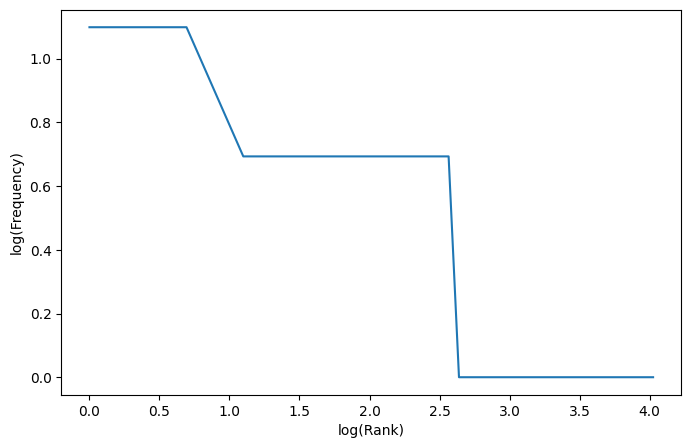


Top 5 bigrams in S1:
[(('.', 'The'), 5), (('.', 'I'), 4), (('has', 'stopped'), 2), (('stopped', 'syncing'), 2), (('syncing', '.'), 2)]

Top 5 bigrams in S3:
[(('stopped', 'syncing'), 2), (('tried', 'several'), 2), (('several', 'times'), 2), (('student', 'portal'), 2), (('LMS', 'stopped'), 1)]


In [17]:
import re
import math
import pandas as pd
import matplotlib.pyplot as plt
from collections import Counter
from nltk.tokenize import word_tokenize
from nltk.corpus import stopwords
from nltk.stem import PorterStemmer
from nltk.util import bigrams

S1 = [word for ticket in sent for s in ticket for word in word_tokenize(s)]

S2 = [
    word
    for ticket in sent
    for s in ticket
    for word in word_tokenize(re.sub(r"[.?!']", "", s))
]

S3 = list(final_tokens)


porter = PorterStemmer()
S4 = [porter.stem(word) for word in S3]


corpora = {'S1': S1, 'S2': S2, 'S3': S3, 'S4': S4}

stats = []
for name, tokens in corpora.items():
    stats.append({
        'Corpus': name,
        'Total Tokens': len(tokens),
        'Unique Tokens': len(set(tokens)),
        'TTR': len(set(tokens)) / len(tokens)
    })

stats_df = pd.DataFrame(stats)
print(stats_df)


print("Top 10 words in S1:")
print(Counter(S1).most_common(10))

print("\nTop 10 words in S3:")
print(Counter(S3).most_common(10))

freq = Counter(S3).most_common()
ranks = range(1, len(freq) + 1)
frequencies = [count for word, count in freq]

plt.figure(figsize=(8, 5))
plt.plot([math.log(r) for r in ranks],
         [math.log(f) for f in frequencies])
plt.xlabel('log(Rank)')
plt.ylabel('log(Frequency)')
plt.show();

print("\nTop 5 bigrams in S1:")
print(Counter(bigrams(S1)).most_common(5))

print("\nTop 5 bigrams in S3:")
print(Counter(bigrams(S3)).most_common(5))

**Observe:** Why does TTR change from S1 to S4 in your data?

*Your answer:* TTR changes from S1 to S4 because punctuation and stopwords are removed, and stemming combines similar word forms.